[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/02_probability_statistics.ipynb)

# 02 · Probability & Statistics for Machine Learning

**Part 0 — Foundations** · Notebook 2 of 27

Real data is noisy, and ML models are uncertain. Probability is the language for both. This notebook has one big destination: by the end you'll see that **loss functions are not arbitrary choices**. Mean squared error, cross-entropy and even L2 regularization all *fall out* of writing down a probability model and asking "which parameters make the data most likely?"

**What you'll learn**

1. Random variables and discrete distributions (and the law of large numbers)
2. Continuous distributions: densities vs. probabilities
3. Expectation and variance
4. The central limit theorem: why Gaussians are everywhere
5. Joint, marginal and conditional distributions; independence
6. Bayes' rule (and why a 99%-accurate test can still be wrong most of the time)
7. The multivariate Gaussian and covariance matrices
8. Maximum likelihood estimation (MLE)
9. Maximum a posteriori (MAP) estimation and priors
10. **From likelihoods to loss functions**: MSE, cross-entropy, MAE
11. Entropy, cross-entropy and KL divergence

*Course map: CX 4240 Lecture 3 (Probability & Statistics Revisit), Lectures 4 and 6 (Gaussian likelihood → least squares); Bishop, PRML Chapter 2.*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from scipy import stats

Setup complete ✓


---
## 1. Why ML needs probability

Three reasons, each of which this notebook makes concrete:

1. **Data is noisy.** Two apartments with the same size rent for different prices. We model the unexplained part as a *random variable*.
2. **Predictions should carry uncertainty.** "This email is spam with probability 0.93" is more useful than "spam".
3. **It tells us what to optimize.** Writing a probability model and maximizing the likelihood *gives you* the loss function. This is CX 4240's step 2: "derive the loss by MLE or MAP".

---
## 2. Random variables and discrete distributions

A **random variable** $X$ is a quantity whose value is determined by chance. A **discrete** one takes countable values, and is described by its **probability mass function (PMF)** $p(x) = P(X = x)$, with $\sum_x p(x) = 1$.

The three discrete distributions you'll use most:

| Distribution | Models | PMF | Used in |
|---|---|---|---|
| **Bernoulli**$(\phi)$ | one yes/no event | $\phi^x(1-\phi)^{1-x}$, $x\in\{0,1\}$ | binary classification (logistic regression) |
| **Binomial**$(n, \phi)$ | # of successes in $n$ trials | $\binom{n}{k}\phi^k(1-\phi)^{n-k}$ | counting |
| **Categorical**$(\pi_1..\pi_K)$ | one of $K$ outcomes | $\pi_k$ | multiclass classification, next-token prediction in GPT |

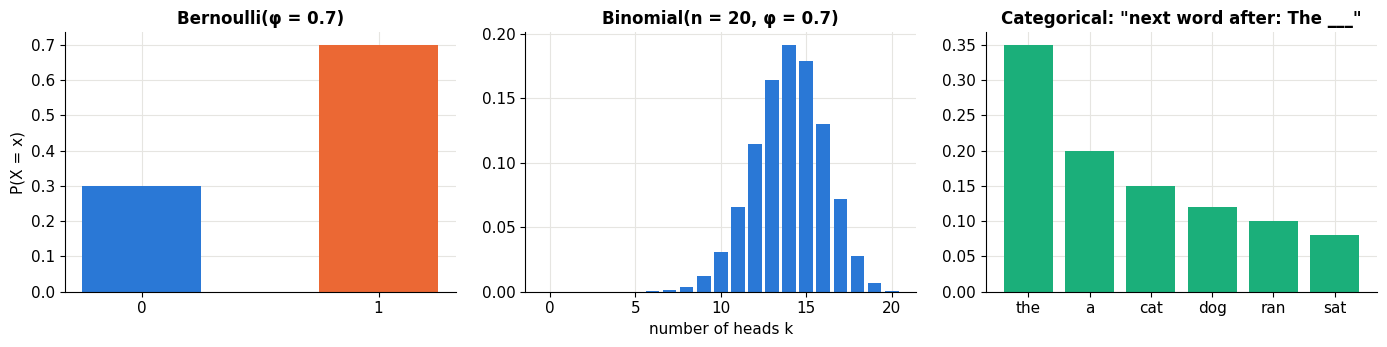

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].bar([0, 1], [0.3, 0.7], color=[C["blue"], C["orange"]], width=0.5)
axes[0].set(xticks=[0, 1], title="Bernoulli(φ = 0.7)", ylabel="P(X = x)")
k = np.arange(0, 21)
axes[1].bar(k, stats.binom.pmf(k, 20, 0.7), color=C["blue"])
axes[1].set(title="Binomial(n = 20, φ = 0.7)", xlabel="number of heads k")
words = ["the", "a", "cat", "dog", "ran", "sat"]
axes[2].bar(words, [0.35, 0.2, 0.15, 0.12, 0.1, 0.08], color=C["aqua"])
axes[2].set(title='Categorical: "next word after: The ___"')
fig.tight_layout(); plt.show()

### 🎬 The law of large numbers

Flip a biased coin ($\phi = 0.7$) over and over and track the **fraction of heads so far**. Each colored line is a separate experiment. Early on they're all over the place; as flips accumulate they all squeeze toward the true value 0.7. This is the **law of large numbers**: sample averages converge to the true expectation. It's why more data gives better estimates.

In [3]:
flips = rng.random((5, 500)) < 0.7
running = np.cumsum(flips, axis=1) / np.arange(1, 501)

fig, ax = plt.subplots(figsize=(8, 4), dpi=80)
lines = [ax.plot([], [], lw=1.6)[0] for _ in range(5)]
ax.axhline(0.7, color=C["ink"], ls="--", lw=1.2, label="true φ = 0.7")
ax.set(xlim=(1, 500), ylim=(0, 1), xscale="log", xlabel="number of flips (log scale)",
       ylabel="fraction of heads so far", title="Law of large numbers")
ax.legend(loc="lower right")
fig.tight_layout()

def frame(f):
    upto = int(np.ceil(500 ** (f / 49)))           # grow on a log scale so early flips are visible
    for i, ln in enumerate(lines):
        ln.set_data(np.arange(1, upto + 1), running[i, :upto])
    return lines

show_anim(animation.FuncAnimation(fig, frame, frames=50, interval=90))

🎚️ **Binomial explorer.** Bars: the exact PMF. Dots: the result of actually simulating 2,000 experiments of $n$ flips each. Notice the shape becomes bell-like as $n$ grows. That's a sneak peek of the central limit theorem (section 5).

In [4]:
def plot_binom(n=10, phi=0.5):
    k = np.arange(0, n + 1)
    sims = rng.binomial(n, phi, size=2000)
    emp = np.bincount(sims, minlength=n + 1) / 2000
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.bar(k, stats.binom.pmf(k, n, phi), color=C["blue"], alpha=0.75, label="exact PMF")
    ax.plot(k, emp, "o", color=C["orange"], label="2,000 simulations")
    ax.set(xlabel="k (number of successes)", ylabel="probability",
           title=f"Binomial(n={n}, φ={phi:.2f}):  mean = nφ = {n*phi:.1f},  var = nφ(1−φ) = {n*phi*(1-phi):.2f}")
    ax.legend(); plt.show()

interact(plot_binom, n=IntSlider(value=10, min=1, max=60, description="n"),
         phi=FloatSlider(value=0.5, min=0.01, max=0.99, step=0.01, description="φ"));

---
> 🚧 **This notebook is being written section by section.** The sections above are complete and run top to bottom; more are on the way.